# 03. Régua de cobrança

**Objetivo:** transformar os scores do modelo numa ação de cobrança para cada cliente da carteira, respondendo à pergunta do projeto: quanto do caixa previsto está em risco e qual abordagem cada cliente deve receber para recuperar esse valor sem desgastar o relacionamento.

**Entrada:** `analytics.client_scores` (probabilidade de atraso e valor esperado em risco, do notebook 02) e `analytics.client_base`.

**Avaliação honesta:** os scores de cada cliente vieram de um modelo que não o viu no treino (validação cruzada), então é possível medir a régua na carteira inteira com o que de fato aconteceu no período.

## 1. Preparação

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists())
sys.path.append(str(ROOT / "src"))

from db import get_engine
from modeling import capture_at_top

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

## 2. Dados

In [2]:
query = """
SELECT
    b.client_id,
    b.recent_max_days_late,
    b.window_amount_due,
    b.target_late_15,
    s.risk_probability,
    s.expected_value_at_risk,
    s.risk_decile
FROM analytics.client_base AS b
INNER JOIN analytics.client_scores AS s
    ON s.client_id = b.client_id
"""
df = pd.read_sql(query, get_engine())
df = df.astype({c: float for c in df.columns if c != "client_id"})

# Valor que de fato ficou em risco: o valor a receber dos clientes que atrasaram mais de 15 dias
df["actual_value_at_risk"] = df["window_amount_due"] * df["target_late_15"]

print(f"{len(df):,} clientes")
print(f"Valor a receber no período: {df['window_amount_due'].sum():,.0f}")
print(f"Valor esperado em risco (modelo): {df['expected_value_at_risk'].sum():,.0f}")
print(f"Valor que de fato ficou em risco: {df['actual_value_at_risk'].sum():,.0f}")

156,333 clientes
Valor a receber no período: 41,581,930,848
Valor esperado em risco (modelo): 637,702,386
Valor que de fato ficou em risco: 722,528,594


## 3. Ordenar por probabilidade ou por valor esperado?

Há duas formas de montar a fila da cobrança:
- **por probabilidade:** primeiro quem tem mais chance de atrasar, qualquer que seja o valor;
- **por valor esperado em risco** (probabilidade × valor a receber): primeiro quem representa mais dinheiro em risco.

A tabela compara as duas: com a mesma quantidade de clientes contatados, quanto dos clientes em risco e quanto do valor em risco cada fila alcança.

In [3]:
rows = []
for share in (0.05, 0.10, 0.20, 0.30):
    for name, score in [("probabilidade", df["risk_probability"]),
                        ("valor esperado", df["expected_value_at_risk"])]:
        cases, value = capture_at_top(df["target_late_15"], score, df["window_amount_due"], share)
        rows.append({"% da carteira contatada": f"{share:.0%}", "fila ordenada por": name,
                     "% dos clientes em risco": cases, "% do valor em risco": value})
queue_table = pd.DataFrame(rows).set_index(["% da carteira contatada", "fila ordenada por"])
queue_table

% dos clientes em risco  \
% da carteira contatada fila ordenada por                            
5%                      probabilidade                        0.322   
                        valor esperado                       0.223   
10%                     probabilidade                        0.439   
                        valor esperado                       0.334   
20%                     probabilidade                        0.576   
                        valor esperado                       0.476   
30%                     probabilidade                        0.667   
                        valor esperado                       0.573   

                                           % do valor em risco  
% da carteira contatada fila ordenada por                       
5%                      probabilidade                    0.264  
                        valor esperado                   0.420  
10%                     probabilidade                    0.400  
                        valor esperado                   0.581  
20%                     probabilidade                    0.565  
                        valor esperado                   0.737  
30%                     probabilidade                    0.659  
                        valor esperado                   0.823

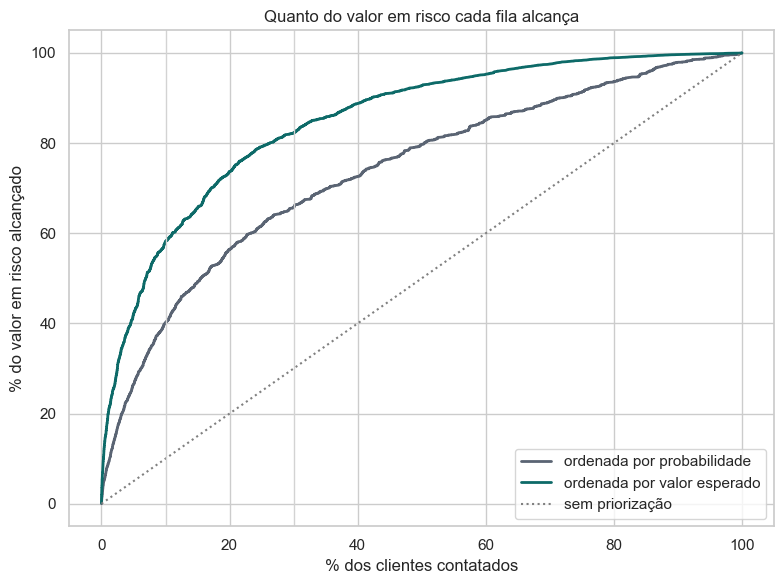

In [4]:
def value_curve(score):
    order = np.argsort(-score.to_numpy(), kind="stable")
    captured = np.cumsum(df["actual_value_at_risk"].to_numpy()[order]) / df["actual_value_at_risk"].sum()
    return np.arange(1, len(df) + 1) / len(df) * 100, captured * 100


fig, ax = plt.subplots(figsize=(8, 6))
for name, score, color in [("ordenada por probabilidade", df["risk_probability"], "#5a6473"),
                           ("ordenada por valor esperado", df["expected_value_at_risk"], "#0d6a68")]:
    x, y = value_curve(score)
    ax.plot(x, y, label=name, color=color, linewidth=2)
ax.plot([0, 100], [0, 100], color="grey", linestyle=":", label="sem priorização")
for share in (10, 30):
    ax.axvline(share, color="lightgrey", linewidth=1)
ax.set_xlabel("% dos clientes contatados")
ax.set_ylabel("% do valor em risco alcançado")
ax.set_title("Quanto do valor em risco cada fila alcança")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_fila_por_valor.png", dpi=150)
plt.show()

## 4. A régua

A fila é ordenada pelo **valor esperado em risco**, porque a pergunta do projeto é sobre caixa. A carteira é dividida em quatro ações, da mais intensa para a mais leve:

| Ação | Quem recebe | O que é |
| --- | --- | --- |
| **Renegociação** | 10% do topo da fila **e** com atraso acima de 30 dias nos 6 meses antes do corte | Oferta de novo acordo de pagamento, para quem já mostra dificuldade |
| **Contato** | Restante dos 10% do topo da fila | Ligação ou mensagem pessoal da equipe antes do vencimento |
| **Lembrete** | Os 20% seguintes da fila | Mensagem automática antes do vencimento |
| **Monitoramento** | Os 70% restantes | Sem ação extra; acompanhamento normal |

Os cortes de 10% e 30% representam uma equipe que consegue atender pessoalmente 1 em cada 10 clientes e mandar mensagens automáticas para mais 2 em cada 10. Na prática, esses cortes seriam ajustados à capacidade real da equipe.

In [5]:
ACTIONS = ["Renegociação", "Contato", "Lembrete", "Monitoramento"]

df["priority_rank"] = df["expected_value_at_risk"].rank(ascending=False, method="first").astype(int)
queue_share = df["priority_rank"] / len(df)

df["collection_action"] = np.select(
    [
        (queue_share <= 0.10) & (df["recent_max_days_late"] > 30),
        queue_share <= 0.10,
        queue_share <= 0.30,
    ],
    ACTIONS[:3],
    default="Monitoramento",
)
df["action_order"] = df["collection_action"].map({a: i for i, a in enumerate(ACTIONS, start=1)})

total_actual = df["actual_value_at_risk"].sum()
total_cases = df["target_late_15"].sum()
strategy = (
    df.groupby("collection_action")
    .agg(
        clientes=("client_id", "size"),
        taxa_de_risco_real=("target_late_15", "mean"),
        clientes_em_risco=("target_late_15", "sum"),
        valor_a_receber=("window_amount_due", "sum"),
        valor_esperado_em_risco=("expected_value_at_risk", "sum"),
        valor_em_risco_real=("actual_value_at_risk", "sum"),
    )
    .reindex(ACTIONS)
)
strategy.insert(1, "% da carteira", strategy["clientes"] / len(df) * 100)
strategy["% dos clientes em risco"] = strategy["clientes_em_risco"] / total_cases * 100
strategy["% do valor em risco real"] = strategy["valor_em_risco_real"] / total_actual * 100
strategy["taxa_de_risco_real"] = strategy["taxa_de_risco_real"] * 100
strategy

,clientes,% da carteira,taxa_de_risco_real,clientes_em_risco,valor_a_receber,valor_esperado_em_risco,valor_em_risco_real,% dos clientes em risco,% do valor em risco real
collection_action,,,,,,,,,
Renegociação,585,0.374,26.838,157.000,"147,580,586.790","39,181,378.010","41,490,283.860",5.990,5.742
Contato,15048,9.626,4.771,718.000,"11,824,926,432.450","305,833,558.190","378,124,292.520",27.394,52.333
Lembrete,31266,20.000,2.005,627.000,"15,201,158,443.670","171,006,563.360","174,853,959.300",23.922,24.200
Monitoramento,109434,70.001,1.023,"1,119.000","14,408,265,384.810","121,680,886.520","128,060,058.710",42.694,17.724


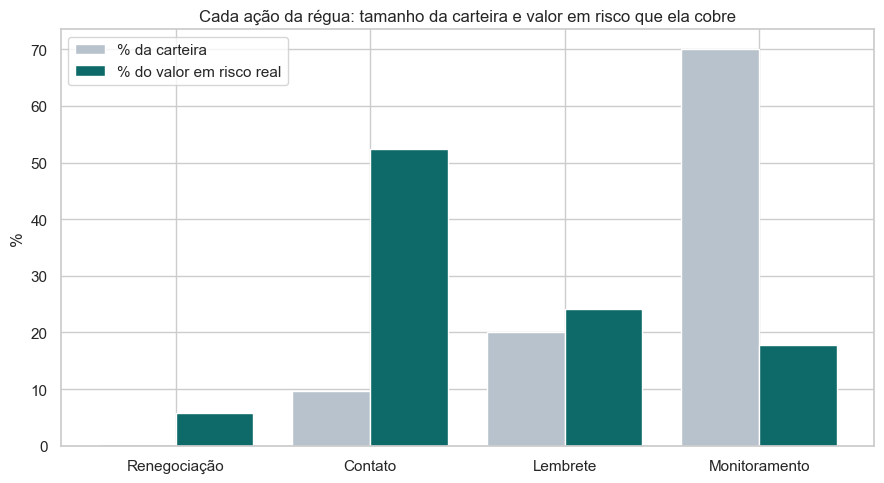

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(ACTIONS))
ax.bar(x - 0.2, strategy["% da carteira"], width=0.4, label="% da carteira", color="#b8c2cc")
ax.bar(x + 0.2, strategy["% do valor em risco real"], width=0.4, label="% do valor em risco real", color="#0d6a68")
ax.set_xticks(x, ACTIONS)
ax.set_ylabel("%")
ax.set_title("Cada ação da régua: tamanho da carteira e valor em risco que ela cobre")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_regua_de_cobranca.png", dpi=150)
plt.show()

## 5. Gravação no banco

A ação de cada cliente e a posição dele na fila são gravadas em `analytics.collection_strategy`, para o Power BI montar a lista priorizada da cobrança.

In [7]:
output = df[["client_id", "priority_rank", "collection_action", "action_order"]]
output.to_sql("collection_strategy", get_engine(), schema="analytics", if_exists="replace",
              index=False, chunksize=10_000)
print(f"{len(output):,} clientes gravados em analytics.collection_strategy")

156,333 clientes gravados em analytics.collection_strategy


## 6. Resumo para a próxima etapa

In [8]:
print("Fila por probabilidade x por valor esperado:")
print(queue_table.round(3).to_string(), "\n")
print("Régua de cobrança:")
print(strategy[["clientes", "% da carteira", "taxa_de_risco_real", "% dos clientes em risco",
                "valor_esperado_em_risco", "% do valor em risco real"]].round(2).to_string())

Fila por probabilidade x por valor esperado:
                                           % dos clientes em risco  % do valor em risco
% da carteira contatada fila ordenada por                                              
5%                      probabilidade                        0.322                0.264
                        valor esperado                       0.223                0.420
10%                     probabilidade                        0.439                0.400
                        valor esperado                       0.334                0.581
20%                     probabilidade                        0.576                0.565
                        valor esperado                       0.476                0.737
30%                     probabilidade                        0.667                0.659
                        valor esperado                       0.573                0.823 

Régua de cobrança:
                   clientes  % da carteira  taxa_de_ri

## 7. Conclusões

**Ordenar pelo valor esperado recupera muito mais dinheiro.** Contatando os mesmos 10% da carteira, a fila por valor esperado alcança 58,1% do valor em risco, contra 40,0% da fila por probabilidade. Com 30% da carteira, chega a 82,3% do valor em risco. A troca é consciente: a fila por valor alcança menos clientes em risco (33,4% contra 43,9% nos 10% do topo), porque prioriza quem representa mais dinheiro. Para uma pergunta de caixa, é a escolha certa.

**A régua concentra o esforço onde está o dinheiro:**
- **Renegociação:** 585 clientes (0,4% da carteira) com taxa real de atraso de 26,8%, cerca de 16 vezes a média. É um grupo pequeno e muito crítico: clientes do topo da fila que já tiveram atraso acima de 30 dias recentemente;
- **Contato:** 15.048 clientes (9,6%) que respondem por 52,3% do valor em risco;
- **Renegociação e contato juntos:** 10% da carteira e 58,1% do valor em risco;
- **Lembrete:** 31.266 clientes (20%) e mais 24,2% do valor em risco;
- **Monitoramento:** 70% da carteira, com taxa de atraso de 1,0% e 17,7% do valor em risco.

**Em resumo:** com ação pessoal em 1 de cada 10 clientes e mensagens automáticas para mais 2 de cada 10, a cobrança cobre 82% do valor que de fato ficou em risco.

**Ponto de atenção:** o valor esperado em risco estimado pelo modelo (637,7 milhões) ficou 12% abaixo do valor que de fato ficou em risco (722,5 milhões). A calibração por quantidade de clientes é boa (notebook 02), mas os atrasos se concentraram um pouco mais em clientes de valor alto do que o modelo previu. Para planejamento de caixa, a estimativa deve ser tratada como um piso.

**Limitação:** os cortes de 10% e 30% representam uma capacidade de equipe hipotética. Na prática, seriam ajustados ao tamanho da equipe e ao custo de cada ação.
